# Data preprocessment

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import librosa
import librosa.display
import numpy as np
import soundfile as sf
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

from scipy.signal import butter, sosfiltfilt
sns.set_theme(style="whitegrid")

In [3]:
# Data and paths
df = pd.read_csv("data/training_data.csv")
files_path = Path("data/training_data")
extension = ".wav"

audio_files = sorted(files_path.rglob("*.wav"))

print(f"Audio files found: {len(audio_files)}")
assert len(audio_files) == 3163# Expected 3163 WAV files. It's on the 1st page of the document the professor gave

Audio files found: 3163


We remove unused columns to keep only the information needed for data preparation, splitting and evaluation.

We keep two labels for each window:
- `patient_murmur`: the original patient label.
- `channel_murmur`: the label based on the recording location.

For `Present` patients, windows from locations listed in `Murmur locations` are labelled `Present`, while the others are labelled `Absent`. For `Absent` and `Unknown` patients, all windows keep the patient's label. Because of this, we end up with more imbalanced classes, but a more correct classification for the networks.

In [4]:
drop = []
for col in df.columns:
    if col not in ["Patient ID", "Murmur", "Recording locations:", "Murmur locations", "Additional ID"]:
        drop.append(col)
df = df.drop(columns=drop)
assert df["Patient ID"].nunique() == len(df)

In [5]:
# Group audio file paths by the patient ID in each filename.
audio_files_by_patient = {}
for audio_file in audio_files:
    patient_id = audio_file.stem.split("_", 1)[0]
    audio_files_by_patient.setdefault(patient_id, []).append(str(audio_file))

# Check that every patient has at least one audio file.
patient_ids = df["Patient ID"].astype(str)
missing_patient_ids = sorted(set(patient_ids) - audio_files_by_patient.keys())
if missing_patient_ids:
    raise FileNotFoundError(f"No audio files found for patient IDs: {missing_patient_ids}")

# Add each patient's list of audio paths, then create one row per recording.

# DON'T RUN THIS CELL MORE THAN 1 TIME, or you will end up with DUPLICATED DATA
df["Audio Path"] = patient_ids.map(audio_files_by_patient)
df = df.explode("Audio Path", ignore_index=True)

df.loc[df["Additional ID"].notna()].head(20)

,Patient ID,Recording locations:,Murmur,Murmur locations,Additional ID,Audio Path
24,23625,AV+PV+TV+MV,Absent,NaN,50379.0,data/training_data/23625_AV.wav
25,23625,AV+PV+TV+MV,Absent,NaN,50379.0,data/training_data/23625_MV.wav
26,23625,AV+PV+TV+MV,Absent,NaN,50379.0,data/training_data/23625_PV.wav
27,23625,AV+PV+TV+MV,Absent,NaN,50379.0,data/training_data/23625_TV.wav
46,36327,AV+PV+TV+MV,Present,MV+PV+TV,49630.0,data/training_data/36327_AV.wav
47,36327,AV+PV+TV+MV,Present,MV+PV+TV,49630.0,data/training_data/36327_MV.wav
48,36327,AV+PV+TV+MV,Present,MV+PV+TV,49630.0,data/training_data/36327_PV.wav
49,36327,AV+PV+TV+MV,Present,MV+PV+TV,49630.0,data/training_data/36327_TV.wav
50,38337,AV+MV,Absent,NaN,49622.0,data/training_data/38337_AV.wav
51,38337,AV+MV,Absent,NaN,49622.0,data/training_data/38337_MV.wav


In [6]:
# Keep the original patient label.
df = df.rename(columns={"Murmur": "patient_murmur"})

# Extract the auscultation location from each recording's filename.
df["Location"] = df["Audio Path"].map(lambda path: Path(path).stem.split("_")[1])

# Absent and Unknown patients keep their labels.
df["channel_murmur"] = df["patient_murmur"]

# Present patients receive a label according to the recording location.
present = df["patient_murmur"].eq("Present")
assert df.loc[present, "Murmur locations"].notna().all()

df.loc[present, "channel_murmur"] = df.loc[present].apply(
    lambda row: ("Present" if row["Location"] in row["Murmur locations"].split("+") else "Absent"),
    axis=1,
)

pd.crosstab(df["patient_murmur"], df["channel_murmur"])

channel_murmur,Absent,Present,Unknown
patient_murmur,,,
Absent,2391,0,0
Present,117,499,0
Unknown,0,0,156


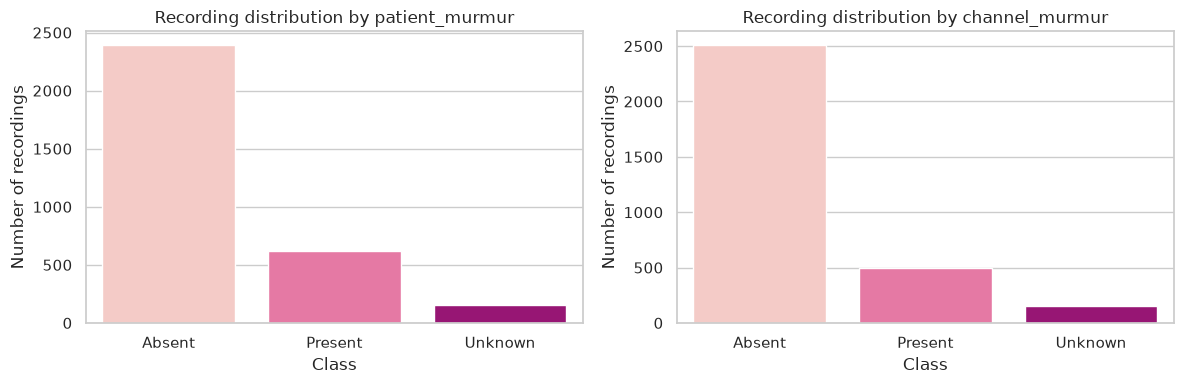

In [7]:
# Verifying the label distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label in zip(axes, ["patient_murmur", "channel_murmur"]):
    sns.countplot(
        data=df, x=label, hue=label,
        order=["Absent", "Present", "Unknown"],
        palette="RdPu", legend=False, ax=ax,
    )
    ax.set_title(f"Recording distribution by {label}")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of recordings")

plt.tight_layout()
plt.show()

## Uniformizing inputs

Firstly, we perform validation steps for all data avaliable, needed for all future implemented architectures.

### 1. Validating the audio files

In [8]:
reports = []

for file in audio_files:
    data, sr = sf.read(file, dtype="float32", always_2d=True)

    report = {
        "file_name": file.name,
        "sample_rate": sr,
        "n_samples": data.shape[0], # if zero - header but no audio
        "duration_s": data.shape[0] / sr,
        "is_empty": data.shape[0] == 0,
        "is_all_zero": bool(np.all(data == 0)),
        "has_nan": bool(np.isnan(data).any()),
        "has_inf": bool(np.isinf(data).any()),
    }

    if report["has_nan"] or report["has_inf"]:
        data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)

    peak = float(np.max(np.abs(data))) if data.size else 0.0
    rms = float(np.sqrt(np.mean(data**2))) if data.size else 0.0
    report["peak"] = peak
    report["rms_db"] = 20 * np.log10(rms) if rms > 0 else -np.inf
    report["peak_db"] = 20 * np.log10(peak) if peak > 0 else -np.inf
    report["out_of_range"] = peak > 1.0

    reports.append(report)

df_report = pd.DataFrame(reports)
df_report.head()


,file_name,sample_rate,n_samples,duration_s,is_empty,is_all_zero,has_nan,has_inf,peak,rms_db,peak_db,out_of_range
0,13918_AV.wav,4000,41152,10.288,False,False,False,False,1.000000,-25.770068,0.000000,False
1,13918_MV.wav,4000,115136,28.784,False,False,False,False,1.000000,-29.029928,0.000000,False
2,13918_PV.wav,4000,37568,9.392,False,False,False,False,1.000000,-27.122108,0.000000,False
3,13918_TV.wav,4000,26368,6.592,False,False,False,False,1.000000,-26.208914,0.000000,False
4,14241_AV.wav,4000,81920,20.480,False,False,False,False,0.999969,-28.275844,-0.000265,False


In [9]:
# Check that every recording has a positive duration.
assert (df_report["duration_s"] > 0).all(), "Found recordings with no duration."

# Check for empty, silent or invalid recordings.
flags = ["is_empty", "is_all_zero", "has_nan", "has_inf", "out_of_range"]
assert not df_report[flags].any().any(), "Found recordings with suspicious values."

# Check that all recordings use the same expected sample rate.
assert (df_report["sample_rate"] == 4000).all(), "Found sample rates other than 4000 Hz."

There aren't any audio files with suspecting values or no duration. Besides that, the sample rate across all of them is of 4000 Hz. Therefore, we don't need to standardize the frequency.

/tmp/ipykernel_90694/1468946307.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df_report, x="duration_s", palette="RdPu")


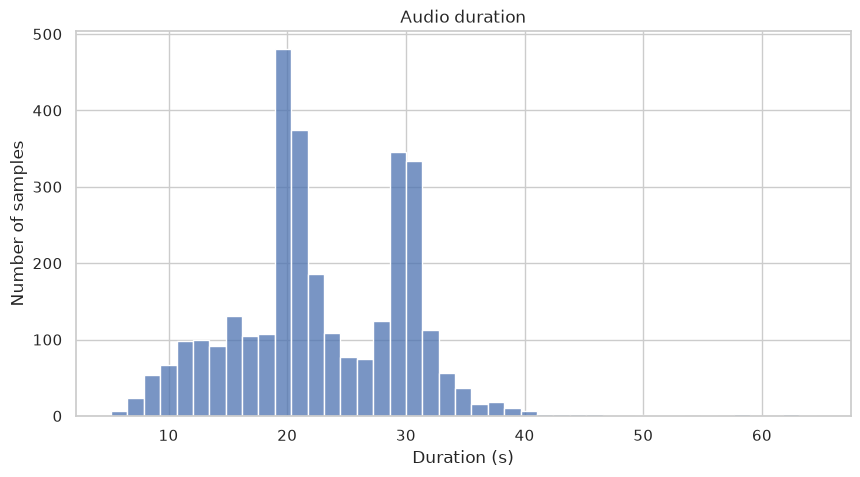

In [10]:
# Verifying the distribution of the duration of the records
plt.figure(figsize=(10, 5))
sns.histplot(data=df_report, x="duration_s", palette="RdPu")
plt.title("Audio duration")
plt.xlabel("Duration (s)")
plt.ylabel("Number of samples")
plt.show()

### 2. Split patients into train/validation and test sets

We split the patients into about 80% for training and validation and 20% for testing. Within the 80%, we use five-fold cross-validation. Each fold is used once for validation while the other four are used for training.

#### Class Imbalance

Most patients are `Absent` and only a few are `Unknown`. So, we use stratification to keep about the same proportion of each patient class in the splits and folds.

#### Preventing Data Leakage

The CirCor dataset was collected during two screening campaigns, in 2014 and 2015.

Some participants attended both campaigns but received different patient IDs. The `Additional ID` column links their records. To prevent data leakage, all recordings from the same person must stay in the same split and fold.

In [11]:
# Use one row per patient when stratifying.
patients = df.drop_duplicates("Patient ID").reset_index(drop=True)
# for example, if we have (1, 2) and (2, 1), they are the same person, so the smaller number is an id.
groups = patients[["Patient ID", "Additional ID"]].min(axis=1).astype(int)

# use one of five folds as the test set (about 20%)
# The remaining 80% will be used for training and validation
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
trainval_idx, test_idx = next(splitter.split(patients, patients["patient_murmur"], groups=groups))
trainval_patients = patients.iloc[trainval_idx].copy().reset_index(drop=True)
trainval_groups = groups.iloc[trainval_idx].to_numpy()

# Split only the remaining 80% into five folds for cross-validation.
# Each fold is used once for validation while the other four are used for training.
trainval_patients["fold"] = -1
for fold, (_, val_idx) in enumerate(splitter.split(trainval_patients, trainval_patients["patient_murmur"], groups=trainval_groups)):
    trainval_patients.loc[val_idx, "fold"] = fold

# Check that no person appears in both subsets or multiple folds.
assert set(trainval_groups).isdisjoint(set(groups.iloc[test_idx]))
assert trainval_patients.groupby(trainval_groups)["fold"].nunique().eq(1).all()

# Select all recordings belonging to the selected patients.
trainval_df = df[df["Patient ID"].isin(trainval_patients["Patient ID"])].copy()
test_df = df[df["Patient ID"].isin(patients.iloc[test_idx]["Patient ID"])].copy()

# Give every recording its patient's fold.
patient_folds = trainval_patients.set_index("Patient ID")["fold"]
trainval_df["fold"] = trainval_df["Patient ID"].map(patient_folds)

### 3. Dealing with noisy data

We compare two preprocessing options: without a band-pass filter and with a 20–600 Hz band-pass filter. This range includes important frequency components of heart sounds and murmurs, but not necessarily all of them. Filtering can reduce noise, but it can also remove useful information, so we use the validation results to compare them.

For each option, we prepare 5-second windows for the CNN and full-recording log-Mel sequences for the RNN. Both use the same patient splits and folds.

Reference for the 20–600 Hz band-pass filter: [Chowdhury et al. (2019), Section 3.1.1](https://pmc.ncbi.nlm.nih.gov/articles/PMC6630694/).

In [12]:
# Split an audio recording into non-overlapping 5 second length windows.
# The final incomplete window is zero-padded, only of its durration is above 2.5s
# If it is shorter than that, we drop the last window

def split_audio_into_windows(audio, sr, window_duration=5):
    window_size = sr * window_duration
    windows = []
    valid_lengths = []
    for start in range(0, len(audio), window_size):
        window = audio[start:start + window_size]
        valid_length = len(window)
        # Pad the final incomplete window with zeros
        if valid_length < 2.5 * 4000:
            break
        if valid_length < window_size:
            window = np.pad(window,(0, window_size - valid_length),mode="constant")
        windows.append(window)
        valid_lengths.append(valid_length)
    return np.array(windows), valid_lengths

In [13]:
def normalize_amplitude(audio):
    peak = np.max(np.abs(audio))
    if peak == 0:
        return audio
    return audio / peak

def clean_noise(audio, bandpass=True):
    if bandpass:
        sos = butter(4, [20, 600], btype="band", fs=4000, output="sos")
        audio = sosfiltfilt(sos, audio)
    return normalize_amplitude(audio)

# Very low RMS - silent or flat
# Peak-to-RMS ratio or high-percentile amplitude - loud burst
# Low fraction of energy in 20-600 Hz - broadband noise

def window_quality(w, raw_w, sr=4000):
    rms = np.sqrt(np.mean(w**2))                               # loudness
    crest = np.max(np.abs(w)) / (rms + 1e-12)                  # high = isolated spikes
    spec = np.abs(np.fft.rfft(raw_w))**2
    freqs = np.fft.rfftfreq(len(raw_w), 1/sr)
    band_ratio = spec[(freqs >= 20) & (freqs <= 600)].sum() / (spec.sum() + 1e-12)
    return {"rms": rms, "crest": crest, "band_ratio": band_ratio}

For the CNN, we follow this pipeline:

1. Apply the 20–600 Hz band-pass filter only for the filtered option, then normalize each recording by its maximum absolute amplitude. Silent recordings are left unchanged to avoid division by zero.

2. Divide the waveform into non-overlapping 5-second windows.

3. Keep and zero-pad the final incomplete window if it lasts at least 2.5 seconds. Otherwise, discard it.

In [14]:
splits = [("trainval", trainval_df), ("test", test_df)]
windows_dir = Path("data/processed/windows")

for option in ["unfiltered", "filtered"]:
    win_dir = windows_dir / option
    win_dir.mkdir(parents=True, exist_ok=True)

    for split, split_df in splits:
        X, meta = [], []
        for _, row in split_df.iterrows():
            audio_path = row["Audio Path"]
            audio, sr = sf.read(audio_path, dtype="float32")
            recording_id = Path(audio_path).stem

            windows, valid_lengths = split_audio_into_windows(audio=clean_noise(audio, bandpass=(option == "filtered")),sr=sr)
            raw_windows, _ = split_audio_into_windows(audio=audio, sr=sr)
            assert len(windows) == len(raw_windows)

            for window_id, (window, raw_window, valid_length) in enumerate(zip(windows, raw_windows, valid_lengths)):
                quality = window_quality(window[:valid_length], raw_window[:valid_length], sr=sr)
                X.append(window)
                meta.append({
                    "Patient ID": row["Patient ID"],
                    "Additional ID": row["Additional ID"],
                    "Recording ID": recording_id,
                    "Location": row["Location"],
                    "Window ID": window_id,
                    "Valid Length": valid_length,
                    "patient_murmur": row["patient_murmur"],
                    "channel_murmur": row["channel_murmur"],
                    "fold": row.get("fold", -1), # in the test set there are no folds numbers, so we use -1.
                    **quality,
                })
        X = np.stack(X).astype("float32")[..., None]
        meta_df = pd.DataFrame(meta)
        np.save(win_dir / f"X_{split}_windows.npy", X)
        meta_df.to_csv(win_dir / f"meta_{split}_windows.csv", index=False)
        print(f"{option}, {split}: X={X.shape}, windows={len(meta_df)}")

unfiltered, trainval: X=(11620, 20000, 1), windows=11620
unfiltered, test: X=(2796, 20000, 1), windows=2796
filtered, trainval: X=(11620, 20000, 1), windows=11620
filtered, test: X=(2796, 20000, 1), windows=2796


We thought about removing low-quality windows and will test whether this improves the results. For each fold, we use its training data to calculate the thresholds and flag which windows to keep. For now, all windows are exported.

In [15]:
for option in ["unfiltered", "filtered"]:
    win_dir = windows_dir / option
    path = win_dir / "meta_trainval_windows.csv"
    meta = pd.read_csv(path)

    for fold in range(5):
        # Only use the training windows of this fold to calculate thresholds.
        tr = meta[meta["fold"] != fold]
        thr = {"rms_lo": np.percentile(tr["rms"], 1),
               "crest_hi": np.percentile(tr["crest"], 99),
               "band_lo": np.percentile(tr["band_ratio"], 1)}

        meta[f"noisy_fold_{fold}"] = (
            (meta["rms"] < thr["rms_lo"])
            | (meta["crest"] > thr["crest_hi"])
            | (meta["band_ratio"] < thr["band_lo"])
        )
        meta[f"keep_fold_{fold}"] = ~meta[f"noisy_fold_{fold}"]

    meta.to_csv(path, index=False)

### 2D CNN using log-Mel spectograms

A **log-Mel spectrogram** is a time-frequency "image" of the audio. Each 5 s window goes through three steps:

1. **STFT**: slide a short window (`n_fft` samples) along the signal in steps of `hop_length` samples and take an FFT in each one. This gives the energy at each frequency over time.

2. **Mel filterbank**: group the linear FFT bins into `n_mels` overlapping triangular bands, spaced on the mel scale (narrow at low frequencies, wide at high ones). This compresses the frequency axis and emphasizes the low frequencies where heart sounds live.

3. **Log**: convert power to a log (dB) scale. Raw power spans many orders of magnitude (S1/S2 are far louder than a murmur), and the log makes quiet and loud structure comparable. A small floor (`amin`) avoids `log(0)`.

The result is a 2D array of shape `(n_mels, time_frames)`, which the CNN treats as a one-channel image: frequency on the vertical axis, time on the horizontal axis.

**Parameters:** `n_fft=256` (64 ms), `hop_length=128` (32 ms), and frequencies from 0 to 2000 Hz. We compare 64 and 128 Mel bands while keeping the other settings fixed. Each 5 s window gives 157 frames, so the CNN input shape is `(64, 157, 1)` or `(128, 157, 1)`.

In [16]:
SR = 4000
WINDOW_S = 5
N_FFT = 256
HOP = 128
N_MELS = 64 # plots
MEL_BANDS = [64, 128]
FMIN, FMAX = 0, 2000
AMIN = 1e-10
N_FRAMES = 1 + (SR * WINDOW_S) // HOP   # 157

# The Librosa library automatically does the conversion for log-Mel spectograms
def window_to_logmel(window, n_mels=N_MELS):
    """Waveform -> log-Mel spectrogram (Mel bands, time frames) in dB."""
    mel = librosa.feature.melspectrogram(
        y=window, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=n_mels, fmin=FMIN, fmax=FMAX, power=2.0)
    return librosa.power_to_db(mel, ref=1.0, amin=AMIN, top_db=None).astype("float32")

print(f"Frequency resolution: {SR / N_FFT:.1f} Hz/bin | window: {1000*N_FFT/SR:.0f} ms | hop: {1000*HOP/SR:.0f} ms")
for n_mels in MEL_BANDS:
    print(f"Expected CNN input shape: ({n_mels}, {N_FRAMES}, 1)")

Frequency resolution: 15.6 Hz/bin | window: 64 ms | hop: 32 ms
Expected CNN input shape: (64, 157, 1)
Expected CNN input shape: (128, 157, 1)


The four panels show each stage for the first 5s of one recording: the waveform, the linear-frequency STFT (dB), the Mel spectrogram in raw power, and the final log-Mel. The raw-power panel is mostly dark, which is why the log step is needed.

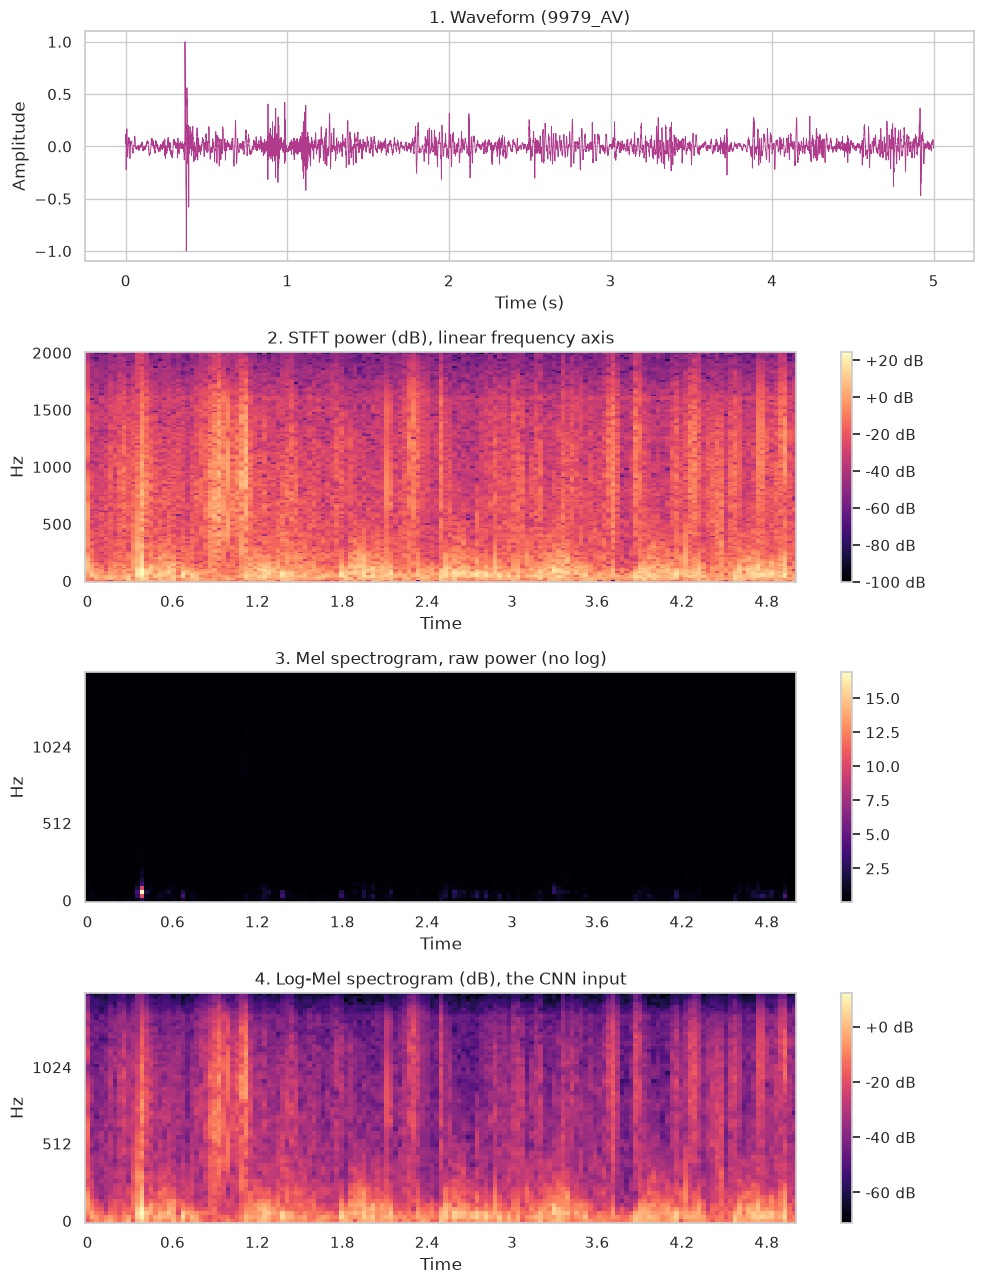

In [17]:
def first_window(df_, murmur):
    """First 5-second window from a recording with the given patient label."""
    sub = df_[df_["patient_murmur"] == murmur]
    row = sub.iloc[0]
    audio, sr = sf.read(row["Audio Path"], dtype="float32")
    assert sr == SR
    windows, _ = split_audio_into_windows(normalize_amplitude(audio), sr, WINDOW_S)
    return windows[0], Path(row["Audio Path"]).stem

w, name = first_window(trainval_df, "Present")
t = np.arange(len(w)) / SR

stft_db = librosa.power_to_db(np.abs(librosa.stft(w, n_fft=N_FFT, hop_length=HOP))**2,
                              ref=1.0, amin=AMIN, top_db=None)
mel_power = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                           n_mels=N_MELS, fmin=FMIN, fmax=FMAX)
logmel = window_to_logmel(w)

fig, ax = plt.subplots(4, 1, figsize=(10, 13))
ax[0].plot(t, w, lw=0.6, color="#b03a8c")
ax[0].set(title=f"1. Waveform ({name})", xlabel="Time (s)", ylabel="Amplitude")

im = librosa.display.specshow(stft_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="linear", ax=ax[1], cmap="magma")
ax[1].set_title("2. STFT power (dB), linear frequency axis"); fig.colorbar(im, ax=ax[1], format="%+.0f dB")

im = librosa.display.specshow(mel_power, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                              fmin=FMIN, fmax=FMAX, ax=ax[2], cmap="magma")
ax[2].set_title("3. Mel spectrogram, raw power (no log)"); fig.colorbar(im, ax=ax[2])

im = librosa.display.specshow(logmel, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                              fmin=FMIN, fmax=FMAX, ax=ax[3], cmap="magma")
ax[3].set_title("4. Log-Mel spectrogram (dB), the CNN input"); fig.colorbar(im, ax=ax[3], format="%+.0f dB")

plt.tight_layout(); plt.show()

In [18]:
label_map = {"Absent": 0, "Present": 1, "Unknown": 2}

def load_windows(split, option):
    win_dir = windows_dir / option
    X = np.load(win_dir / f"X_{split}_windows.npy", mmap_mode="r")
    meta = pd.read_csv(win_dir / f"meta_{split}_windows.csv")
    return X, meta

In [19]:
for option in ["unfiltered", "filtered"]:
    for n_mels in MEL_BANDS:
        out_dir = Path("data/processed/cnn_2d") / option / f"mel_{n_mels}"
        out_dir.mkdir(parents=True, exist_ok=True)

        for split in ["trainval", "test"]:
            Xw, meta_df = load_windows(split, option)
            X = np.stack([window_to_logmel(w[:, 0], n_mels=n_mels) for w in Xw]).astype("float32")[..., None]
            y_patient = meta_df["patient_murmur"].map(label_map).to_numpy()
            y_channel = meta_df["channel_murmur"].map(label_map).to_numpy()
            groups = meta_df["Patient ID"].to_numpy()

            assert X.shape == (len(meta_df), n_mels, N_FRAMES, 1)
            assert not meta_df[["patient_murmur", "channel_murmur", "fold"]].isna().any().any()
            assert np.isfinite(X).all()

            np.save(out_dir / f"X_{split}_2d.npy", X)
            np.save(out_dir / f"y_patient_{split}_2d.npy", y_patient)
            np.save(out_dir / f"y_channel_{split}_2d.npy", y_channel)
            np.save(out_dir / f"groups_{split}_2d.npy", groups)
            meta_df.to_csv(out_dir / f"meta_{split}_2d.csv", index=False)
            print(f"{option}, {n_mels} Mel bands, {split}: X={X.shape}")

unfiltered, 64 Mel bands, trainval: X=(11620, 64, 157, 1)
unfiltered, 64 Mel bands, test: X=(2796, 64, 157, 1)
unfiltered, 128 Mel bands, trainval: X=(11620, 128, 157, 1)
unfiltered, 128 Mel bands, test: X=(2796, 128, 157, 1)
filtered, 64 Mel bands, trainval: X=(11620, 64, 157, 1)
filtered, 64 Mel bands, test: X=(2796, 64, 157, 1)
filtered, 128 Mel bands, trainval: X=(11620, 128, 157, 1)
filtered, 128 Mel bands, test: X=(2796, 128, 157, 1)


### RNN

For the RNN, we convert each full recording into a log-Mel sequence with shape (time frames, n_mels), where n_mels is 64 or 128. Recordings have different lengths, so we save their arrays in an `.npz` file, identified by `Recording ID`.

The metadata has one row per recording and includes both labels, the patient ID, the fold and the number of frames. Padding and masking are handled in the RNN notebook.

In [20]:
for option in ["unfiltered", "filtered"]:
    for n_mels in MEL_BANDS:
        out_dir = Path("data/processed/rnn") / option / f"mel_{n_mels}"
        out_dir.mkdir(parents=True, exist_ok=True)

        for split, split_df in splits:
            X, meta = {}, []

            for _, row in split_df.iterrows():
                audio, sr = sf.read(row["Audio Path"], dtype="float32")
                assert sr == SR
                recording_id = Path(row["Audio Path"]).stem
                audio = clean_noise(audio, bandpass=(option == "filtered"))

                # Full recording, without padding: (time frames, Mel bands).
                spectrogram = window_to_logmel(audio, n_mels=n_mels).T
                assert spectrogram.shape[1] == n_mels
                assert np.isfinite(spectrogram).all()
                assert recording_id not in X
                X[recording_id] = spectrogram

                meta.append({
                    "Patient ID": row["Patient ID"],
                    "Additional ID": row["Additional ID"],
                    "Recording ID": recording_id,
                    "Location": row["Location"],
                    "Valid Frames": spectrogram.shape[0],
                    "patient_murmur": row["patient_murmur"],
                    "channel_murmur": row["channel_murmur"],
                    "fold": row.get("fold", -1), # The test set has no fold assigned, so we use -1.
                })

            meta_df = pd.DataFrame(meta)
            y_patient = meta_df["patient_murmur"].map(label_map).to_numpy()
            y_channel = meta_df["channel_murmur"].map(label_map).to_numpy()
            groups = meta_df["Patient ID"].to_numpy()

            assert not meta_df[["patient_murmur", "channel_murmur", "fold"]].isna().any().any()

            np.savez(out_dir / f"X_{split}_rnn.npz", **X)
            np.save(out_dir / f"y_patient_{split}_rnn.npy", y_patient)
            np.save(out_dir / f"y_channel_{split}_rnn.npy", y_channel)
            np.save(out_dir / f"groups_{split}_rnn.npy", groups)
            meta_df.to_csv(out_dir / f"meta_{split}_rnn.csv", index=False)
            print(f"{option}, {n_mels} Mel bands, {split}: {len(meta_df)} recordings")

unfiltered, 64 Mel bands, trainval: 2537 recordings
unfiltered, 64 Mel bands, test: 626 recordings
unfiltered, 128 Mel bands, trainval: 2537 recordings
unfiltered, 128 Mel bands, test: 626 recordings
filtered, 64 Mel bands, trainval: 2537 recordings
filtered, 64 Mel bands, test: 626 recordings
filtered, 128 Mel bands, trainval: 2537 recordings
filtered, 128 Mel bands, test: 626 recordings
